In [1]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse
import gzip

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
from collections import OrderedDict
import plotly.express as px
import plotly.graph_objects as go
from matplotlib.cm import ScalarMappable
from scipy.ndimage import gaussian_filter

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:651: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:726: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)


In [2]:
#read Umap samples list
fresh_Hap1_K562 = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file_2/fresh_Hap1_K562.csv", sep=' ',index_col=0)
fresh_G1_proM = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file_2/fresh_G1_proM.csv", sep=' ',index_col=0)
fixlysis_Hap1_K562 = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file_2/fixlysis_Hap1_K562.csv", sep=' ',index_col=0)
fixlysis_G1_proM = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file_2/fixlysis_G1_proM.csv", sep=' ',index_col=0)

In [3]:
fixlysis_G1_proM

,UMAP_1,UMAP_2,clusters,originalbatch,originalbatch.1
AGKFOLHK,0.347901,-0.100768,0,1,proM
BIQLYGWQ,4.180230,-1.114531,0,1,G1
BLATYPKG,2.433614,-0.362962,0,1,G1
CAUOUQFQ,4.024606,-0.627020,0,1,proM
CGBINFXN,-1.590370,-0.200330,0,1,G1
...,...,...,...,...,...
YVLUMZVG,-0.371191,-0.571105,0,3,G1
ZIAJXOVC,-7.460190,-1.362099,1,3,G1
ZKUSFLKT,2.545911,1.892046,0,3,G1
ZNZVGQME,0.288624,-0.697131,0,3,G1


<Figure size 600x600 with 0 Axes>

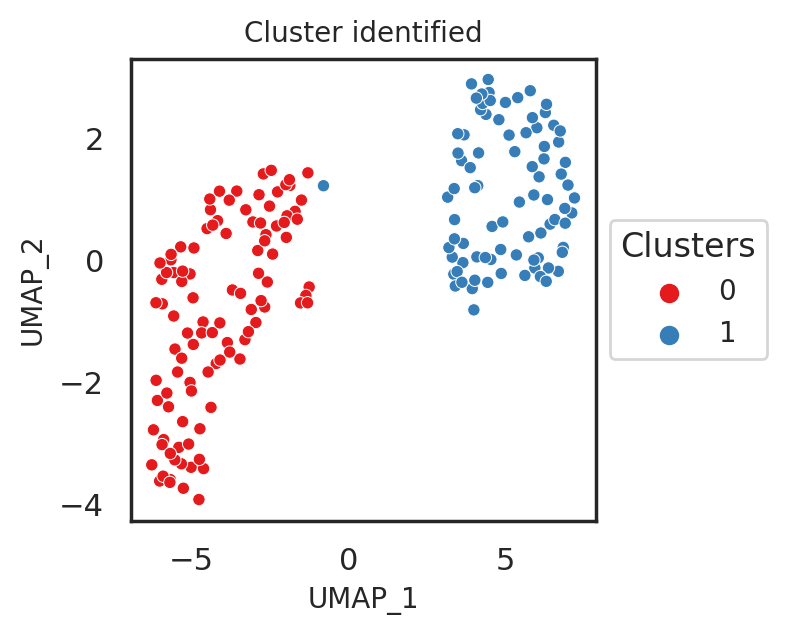

In [4]:
#plot the fresh 2 cells mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fresh_Hap1_K562, x='UMAP_1', y='UMAP_2', hue='clusters', palette="Set1", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('Cluster identified',fontsize = 10)

# Show legend
plt.legend(title='Clusters', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fresh_2cells_cluster.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

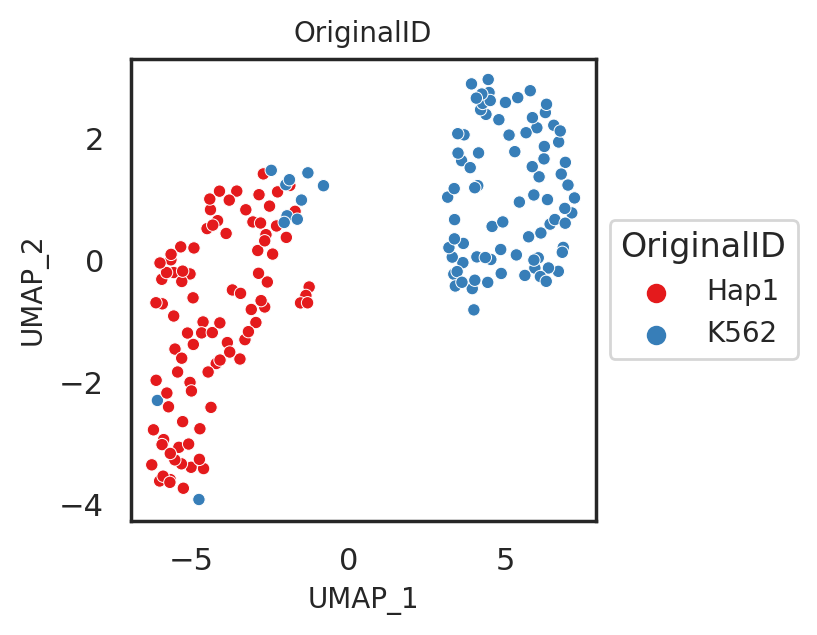

In [5]:
#plot the fresh 2 cells mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fresh_Hap1_K562, x='UMAP_1', y='UMAP_2', hue='originalID', palette="Set1", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('OriginalID',fontsize = 10)

# Show legend
plt.legend(title='OriginalID', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fresh_2cells_originalID.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

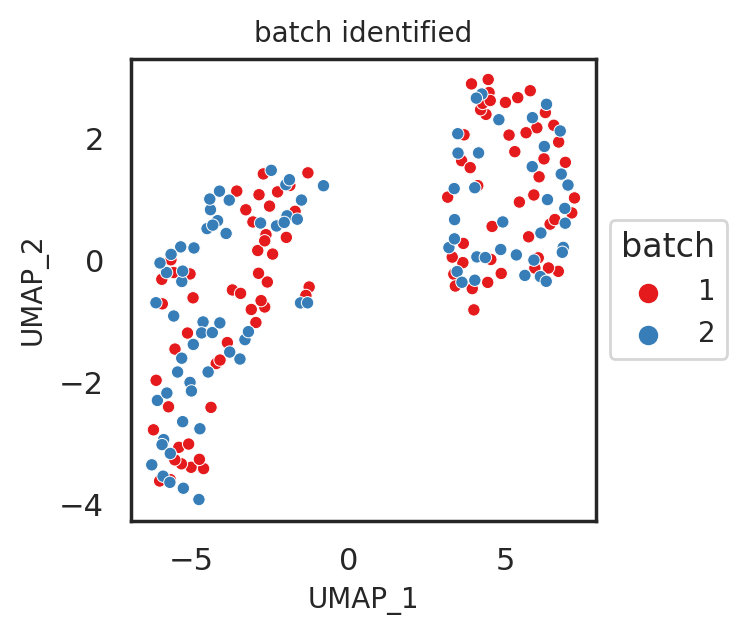

In [ ]:
#plot the fresh 2 cells mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fresh_Hap1_K562, x='UMAP_1', y='UMAP_2', hue='originalbatch', palette="Set1", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('batch identified',fontsize = 10)

# Show legend
plt.legend(title='batch', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fresh_2cells_originalbatch.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

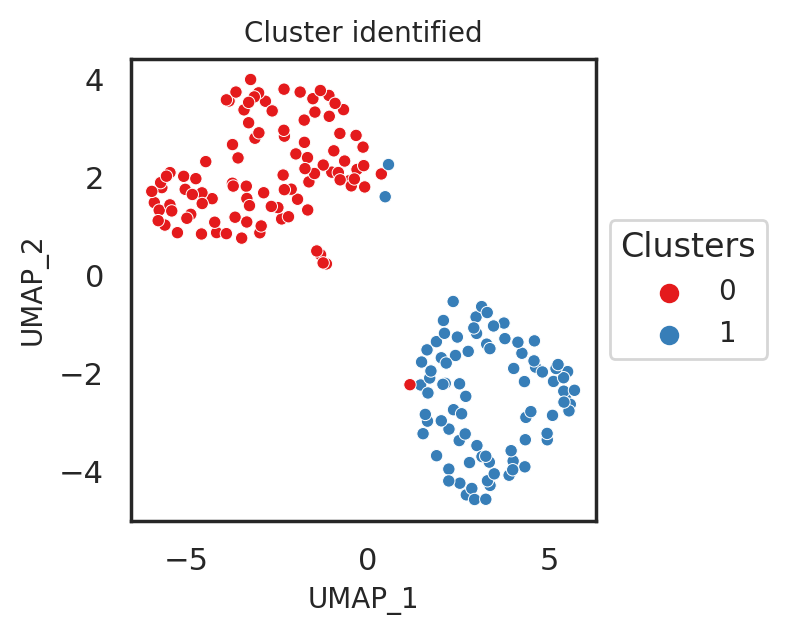

In [7]:
#plot the fresh 2 cells mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fixlysis_Hap1_K562, x='UMAP_1', y='UMAP_2', hue='clusters', palette="Set1", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('Cluster identified',fontsize = 10)

# Show legend
plt.legend(title='Clusters', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fixlysis_2cells_cluster.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

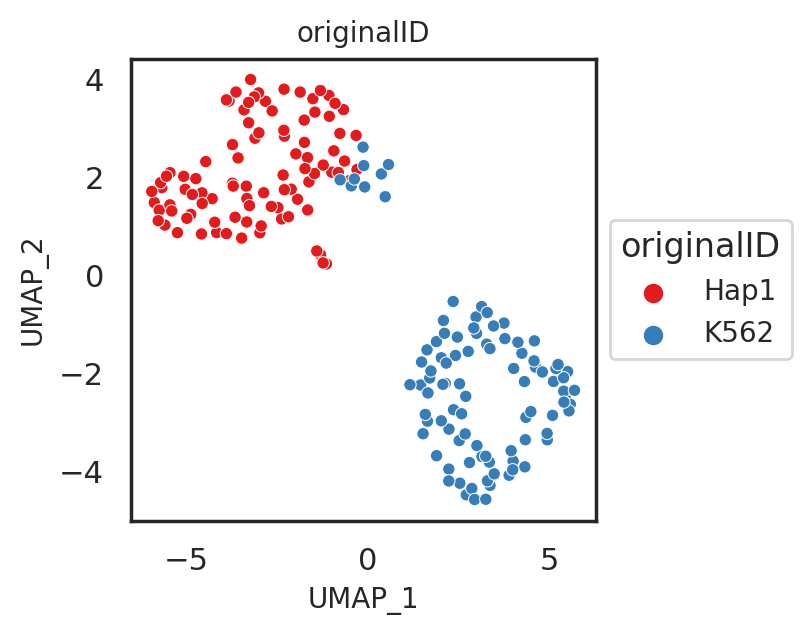

In [8]:
#plot the fixlysis 2 cells mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fixlysis_Hap1_K562, x='UMAP_1', y='UMAP_2', hue='originalID', palette="Set1", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('originalID',fontsize = 10)

# Show legend
plt.legend(title='originalID', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fixlysis_2cells_originalID.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

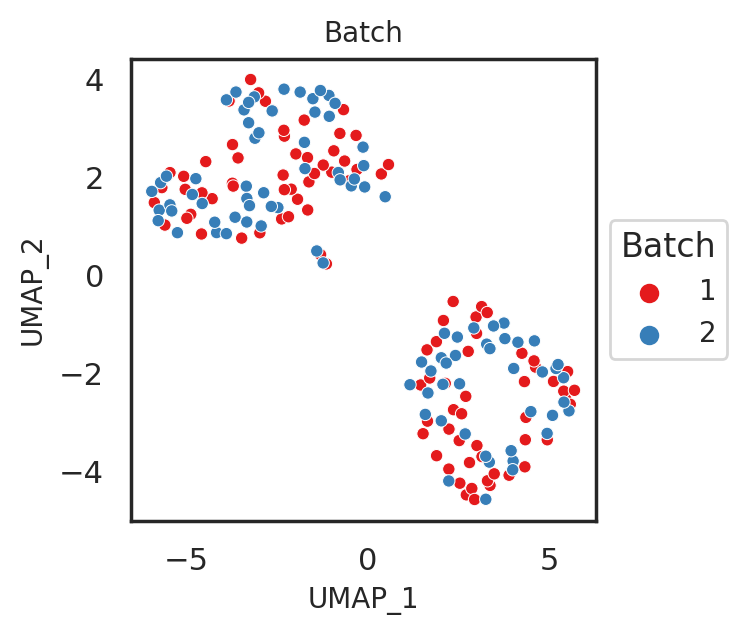

In [9]:
#plot the fixlysis 2 cells mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fixlysis_Hap1_K562, x='UMAP_1', y='UMAP_2', hue='originalbatch', palette="Set1", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('Batch',fontsize = 10)

# Show legend
plt.legend(title='Batch', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fixlysis_2cells_originalbatch.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

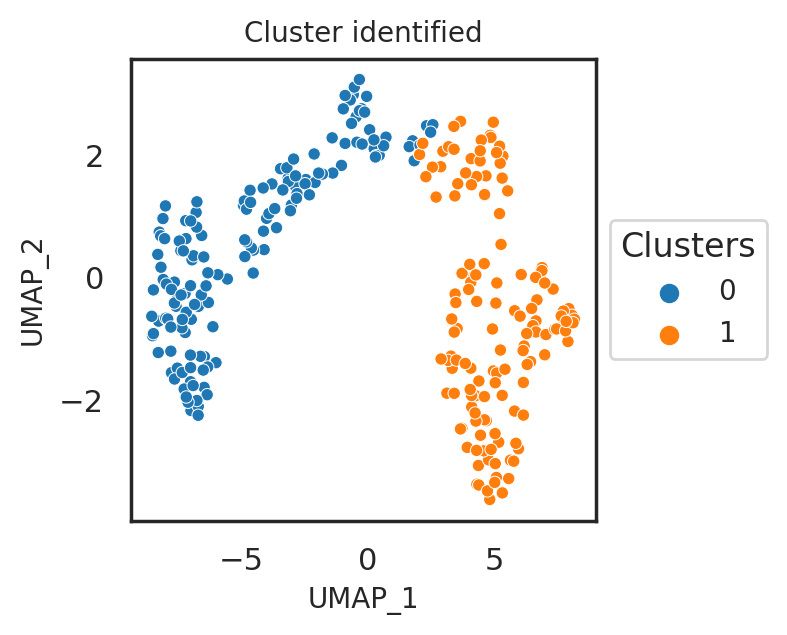

In [10]:
#plot the fresh proM&G1 mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fresh_G1_proM, x='UMAP_1', y='UMAP_2', hue='clusters', palette="tab10", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('Cluster identified',fontsize = 10)

# Show legend
plt.legend(title='Clusters', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fresh_proM_G1_cluster.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

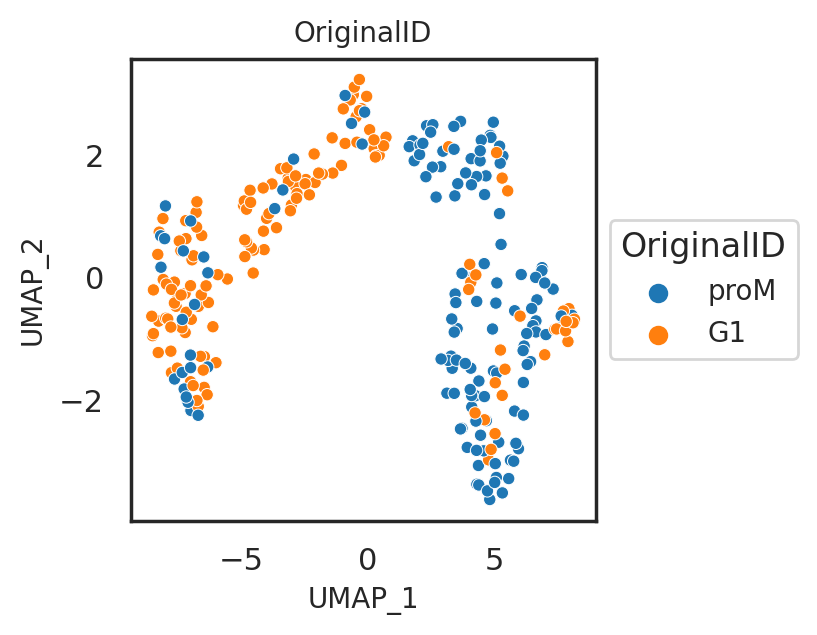

In [11]:
#plot the fresh proM&G1 mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fresh_G1_proM, x='UMAP_1', y='UMAP_2', hue='originalbatch.1', palette="tab10", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('OriginalID',fontsize = 10)

# Show legend
plt.legend(title='OriginalID', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fresh_proM_G1_originalID.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

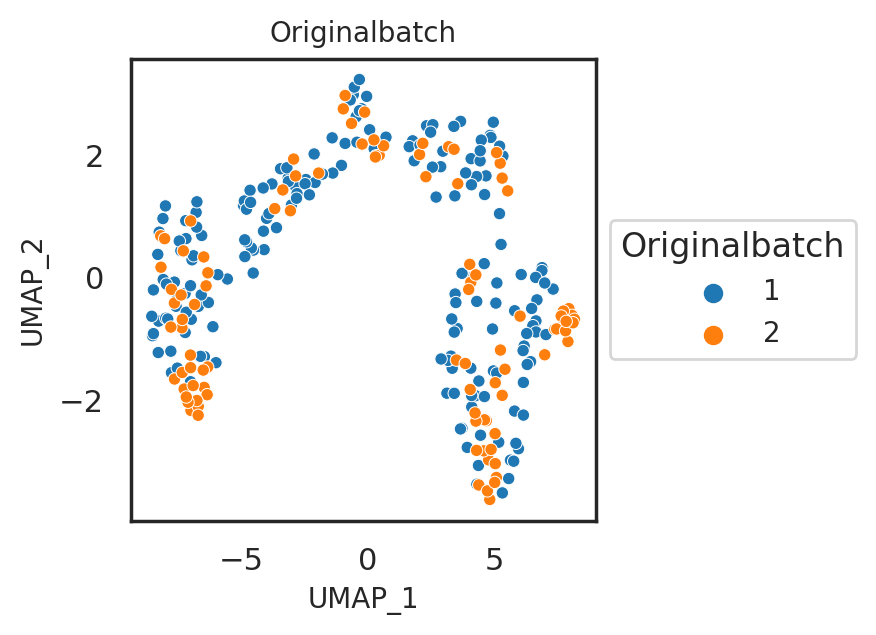

In [12]:
#plot the fresh proM&G1 mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fresh_G1_proM, x='UMAP_1', y='UMAP_2', hue='originalbatch', palette="tab10", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('Originalbatch',fontsize = 10)

# Show legend
plt.legend(title='Originalbatch', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fresh_proM_G1_originalbatch.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

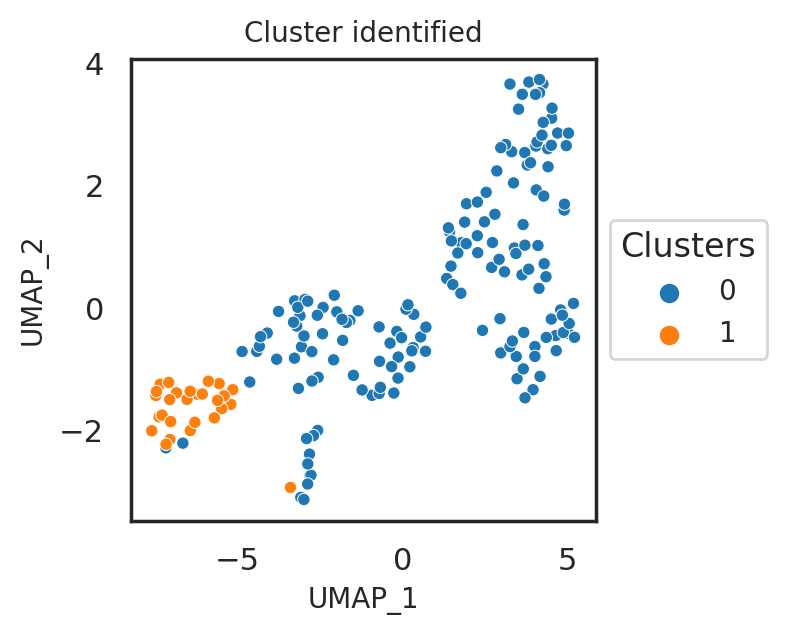

In [13]:
#plot the fixlysis proM&G1 mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fixlysis_G1_proM, x='UMAP_1', y='UMAP_2', hue='clusters', palette="tab10", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('Cluster identified',fontsize = 10)

# Show legend
plt.legend(title='Clusters', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fixlysis_proM_G1_cluster.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

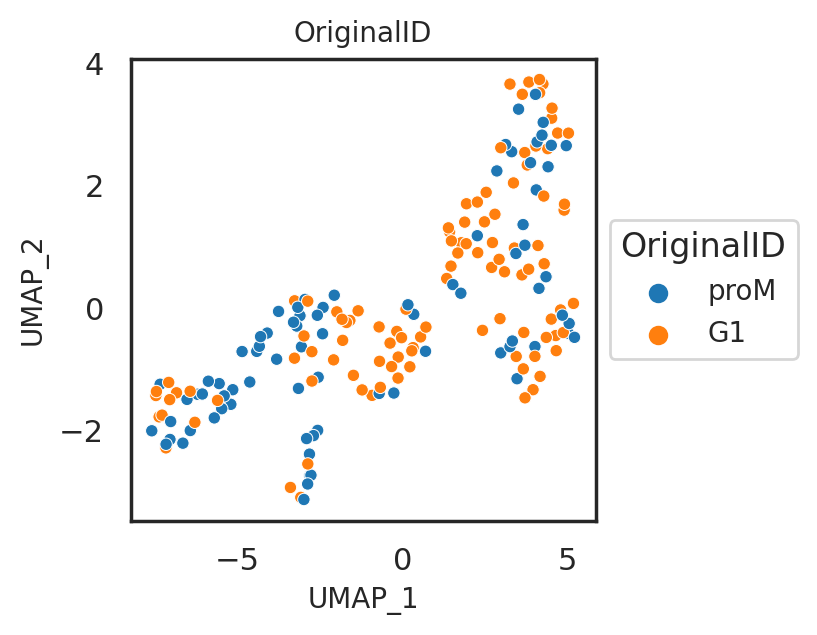

In [14]:
#plot the fixlysis proM&G1 mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fixlysis_G1_proM, x='UMAP_1', y='UMAP_2', hue='originalbatch.1', palette="tab10", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('OriginalID',fontsize = 10)

# Show legend
plt.legend(title='OriginalID', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fixlysis_proM_G1_originalID.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

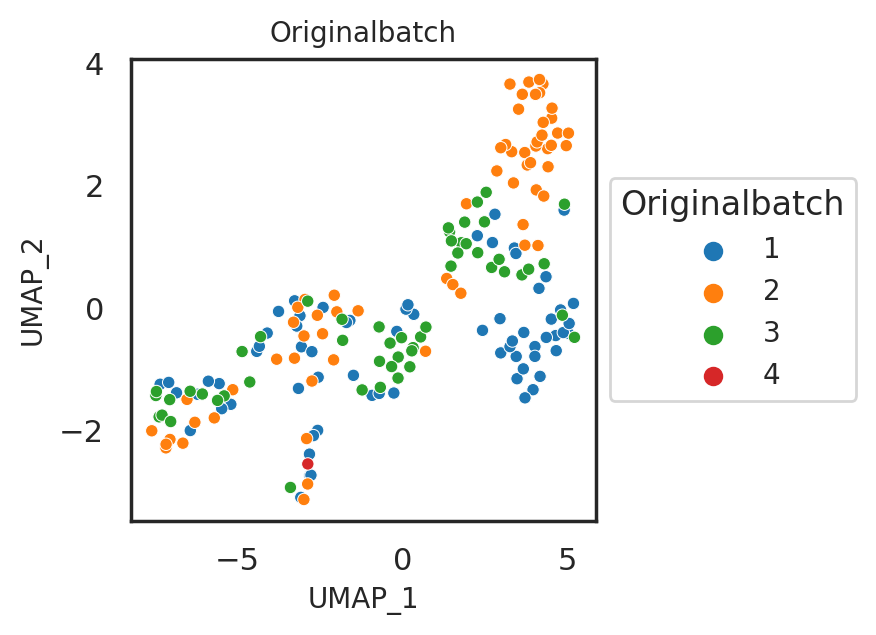

In [15]:
#plot the fixlysis proM&G1 mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=fixlysis_G1_proM, x='UMAP_1', y='UMAP_2', hue='originalbatch', palette="tab10", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('Originalbatch',fontsize = 10)

# Show legend
plt.legend(title='Originalbatch', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_fixlysis_proM_G1_originalbatch.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

In [16]:
#plot the downsampling fixlysis two cells Umap

In [18]:
fixlysis_1percent = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/downsampling/fixlysis_downsampling_umap_1percent.csv", sep=' ',index_col=0)
fixlysis_5percent = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/downsampling/fixlysis_downsampling_umap_5percent.csv", sep=' ',index_col=0)
fixlysis_10percent = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/downsampling/fixlysis_downsampling_umap_10percent.csv", sep=' ',index_col=0)
fixlysis_25percent = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/downsampling/fixlysis_downsampling_umap_25percent.csv", sep=' ',index_col=0)
fixlysis_50percent = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/downsampling/fixlysis_downsampling_umap_55percent.csv", sep=' ',index_col=0)

In [19]:
fixlysis_50percent

,UMAP_1,UMAP_2,clusters,originalbatch,originalbatch.1
ACWAFKQZ,-8.468080,-5.150794,1,1,Hap1
AFOZHRBK,-10.852754,-2.762906,1,1,Hap1
AKFBPPSL,-8.222170,-4.588131,1,1,Hap1
ALKKDXTU,7.496455,2.154760,0,1,K562
AMKWGNVE,6.922409,5.713304,0,1,K562
...,...,...,...,...,...
ZRYIDVPB,8.816105,3.760916,0,2,K562
ZUJDQONE,-8.454502,-3.713307,1,2,Hap1
ZUQTOCRE,8.588810,6.826933,0,2,K562
ZVXHJAFS,-6.766008,-5.962052,1,2,Hap1


<Figure size 600x600 with 0 Axes>

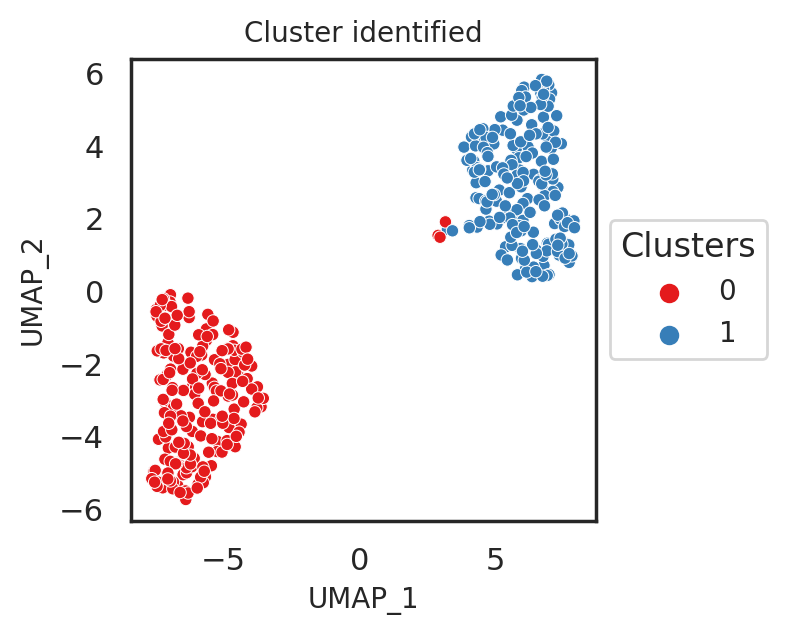

In [43]:
#plot the fresh 2 cells mixtured clusters
sns.set(style="white")

#dataset choose
dataset = fixlysis_10percent
name = "fixlysis_10percent"

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=dataset, x='UMAP_1', y='UMAP_2', hue='clusters', palette="Set1", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('Cluster identified',fontsize = 10)

# Show legend
plt.legend(title='Clusters', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_2cells_cluster_{name}.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

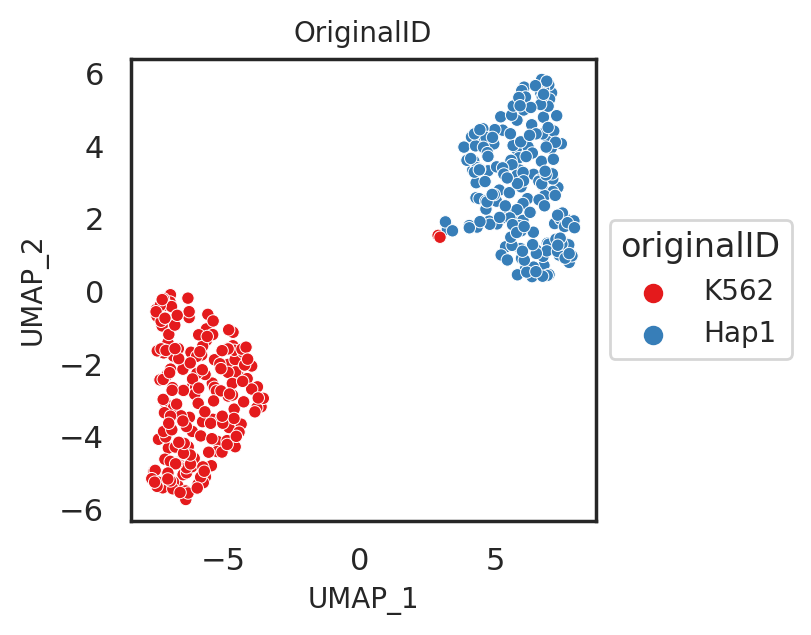

In [44]:
#plot the fresh 2 cells mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=dataset, x='UMAP_1', y='UMAP_2', hue='originalbatch.1', palette="Set1", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('OriginalID',fontsize = 10)

# Show legend
plt.legend(title='originalID', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_2cells_originalID{name}.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

<Figure size 600x600 with 0 Axes>

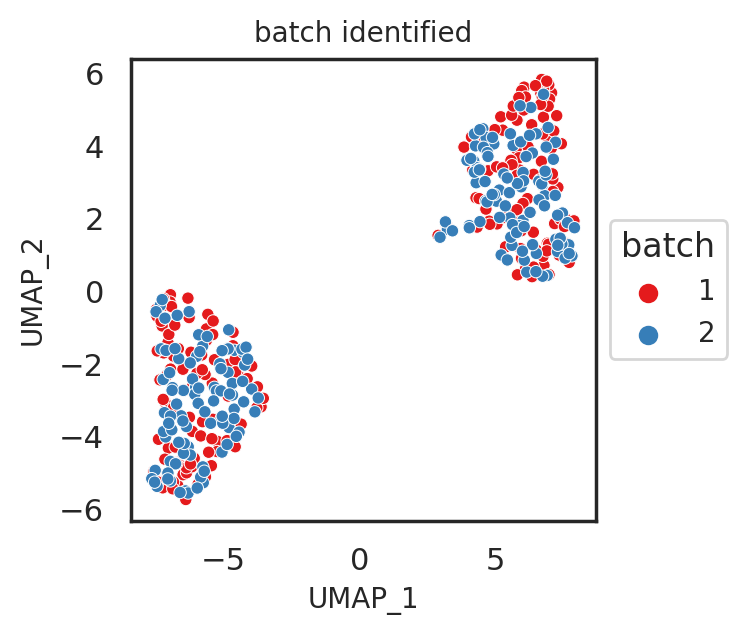

In [45]:
#plot the fresh 2 cells mixtured clusters
sns.set(style="white")

# Create a scatter plot
plt.figure(figsize=(3, 3), dpi=200)
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.scatterplot(data=dataset, x='UMAP_1', y='UMAP_2', hue='originalbatch', palette="Set1", s=20,marker='o')

# Set plot labels and title
plt.xlabel('UMAP_1',fontsize = 10)
plt.ylabel('UMAP_2',fontsize = 10)
plt.title('batch identified',fontsize = 10)

# Show legend
plt.legend(title='batch', bbox_to_anchor=(1, 0.5), loc='center left',fontsize = 10)

# Save the figure
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Umap_2cells_originalID_{name}.pdf", 
            format="pdf", bbox_inches="tight")


# Show the plot
plt.show()

# count genes / reads per cell across conditions

In [2]:
#load UMI matrix
file_path = '/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/'

Fixlysis_Hap1_K562_UMI_matrix = pd.read_csv(f'{file_path}Fixlysis_Hap1_K562_UMI_matrix.txt', sep='\t', index_col=0)
Fixlysis_proM_G1_UMI_matrix = pd.read_csv(f'{file_path}Fixlysis_proM_G1_UMI_matrix.txt', sep='\t', index_col=0)
Fresh_Hap1_K562_UMI_matrix = pd.read_csv(f'{file_path}Fresh_Hap1_K562_UMI_matrix.txt', sep='\t', index_col=0)
Fresh_proM_G1_UMI_matrix = pd.read_csv(f'{file_path}Fresh_proM_G1_UMI_matrix.txt', sep='\t', index_col=0)

In [4]:
#count how many genes detected per cell
def count_genes_detected(matrix):
    """
    Count number of genes (rows) with non-zero UMI for each cell (column).
    """
    return (matrix != 0).sum(axis=0)

# Apply function and save into lists
gene_counts = {
    'Fixlysis_Hap1_K562': count_genes_detected(Fixlysis_Hap1_K562_UMI_matrix).tolist(),
    'Fixlysis_proM_G1': count_genes_detected(Fixlysis_proM_G1_UMI_matrix).tolist(),
    'Fresh_Hap1_K562': count_genes_detected(Fresh_Hap1_K562_UMI_matrix).tolist(),
    'Fresh_proM_G1': count_genes_detected(Fresh_proM_G1_UMI_matrix).tolist()
}

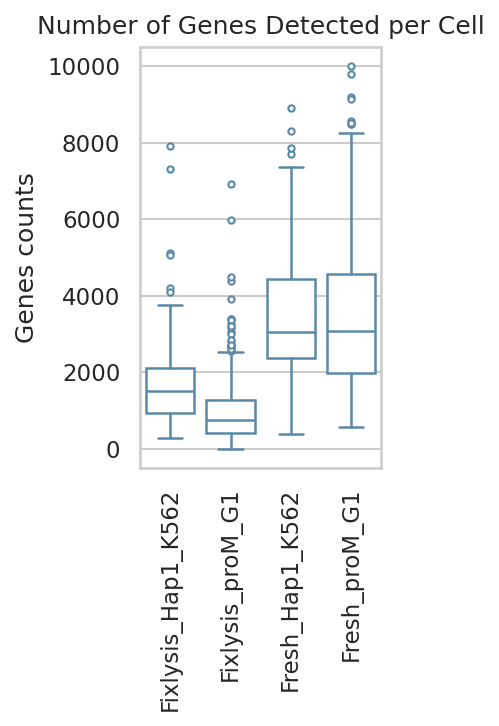

In [39]:
# plot violin plot for gene counts
plt.figure(figsize=(2.8, 5), dpi=150)
ax = sns.boxplot(
    data=violin_df,
    x='Sample',
    y='Genes_Detected',
    linewidth=1.2,
    boxprops=dict(facecolor='white', edgecolor='#5a89a8'),
    medianprops=dict(color='#5a89a8'),
    whiskerprops=dict(color='#5a89a8'),
    capprops=dict(color='#5a89a8'),
    flierprops=dict(marker='o', markerfacecolor='white', markeredgecolor='#5a89a8', markersize=3)
)

# Set x-axis labels
plt.xticks(rotation=90)

# Labels and layout
plt.title('Number of Genes Detected per Cell')
plt.ylabel('Genes counts')
plt.xlabel('')
plt.tight_layout()

# Save the figure
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/Gene_detected_percell.pdf")
plt.show()

In [10]:
#count how many UMI detected per cell
# Define the function
def umi_sum_per_cell(matrix):
    """
    Sum of all UMIs per cell (sum over rows for each column).
    """
    return matrix.sum(axis=0)

# Apply function and save into lists
umi_counts = {
    'Fixlysis_Hap1_K562': umi_sum_per_cell(Fixlysis_Hap1_K562_UMI_matrix).tolist(),
    'Fixlysis_proM_G1': umi_sum_per_cell(Fixlysis_proM_G1_UMI_matrix).tolist(),
    'Fresh_Hap1_K562': umi_sum_per_cell(Fresh_Hap1_K562_UMI_matrix).tolist(),
    'Fresh_proM_G1': umi_sum_per_cell(Fresh_proM_G1_UMI_matrix).tolist()
}

# Create long-form DataFrame for plotting
umi_df = pd.concat([
    pd.DataFrame({'Sample': sample, 'UMI_Counts': values})
    for sample, values in umi_counts.items()
])

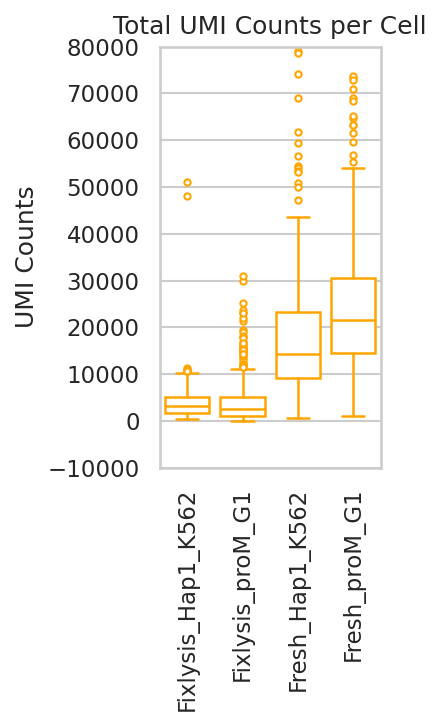

In [38]:
# Plot violin plot for UMI counts
plt.figure(figsize=(2.8, 5), dpi=150)
ax = sns.boxplot(
    data=umi_df,
    x='Sample',
    y='UMI_Counts',
    linewidth=1.2,
    boxprops=dict(facecolor='white', edgecolor='orange'),
    medianprops=dict(color='orange'),
    whiskerprops=dict(color='orange'),
    capprops=dict(color='orange'),
    flierprops=dict(marker='o', markerfacecolor='white', markeredgecolor='orange', markersize=3)
)

# Axis settings
plt.xticks(rotation=90)
plt.ylim(-10000, 80000)

# Labels and layout
plt.title('Total UMI Counts per Cell')
plt.ylabel('UMI Counts')
plt.xlabel('')
plt.tight_layout()

# Save the plot
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/UMI_detected_percell.pdf")
plt.show()